<a href="https://colab.research.google.com/github/aashish7542/ai-learning/blob/main/phase-0-foundations/python/Phase_0_3_mini_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. Project Intro and Objective
# 2. Loading the data

The last notebook became so long thats why we are continutinng the rest of it here. We will first prepare our data for training then train it.

In [46]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/planets.csv"

df = pd.read_csv(url)

# Remove rows where the target is unknown
data = df.dropna(subset=["orbital_period"])

# Separate features and target
X = data[["mass", "method", "distance"]]
y = data["orbital_period"]

print(X.shape)
print(y.shape)

(992, 3)
(992,)


Now we feed the data to scikit learn and split it

In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(793, 3) (199, 3)
(793,) (199,)


**Feature Scaling**

We will now scale some feature using mean and SD formula

**Data Leakage**
We will only use training data when calculating mean, SD or anything else needed for training


In [48]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Learn statistics from training data
mass_train = scaler.fit_transform(X_train[["mass"]])

# Apply the same transformation to test data
mass_test = scaler.transform(X_test[["mass"]])

**Exoplanet Mini-Project**
From Scratch

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/planets.csv"
df = pd.read_csv(url)

data = df.drop(columns = ["number","year"])
data = data.dropna(subset = ["orbital_period"])
x = data.drop(columns = ["orbital_period"])
y = data["orbital_period"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42)
print(x_train.shape,
x_test.shape,
y_train.shape,
y_test.shape)


(793, 3) (199, 3) (793,) (199,)


In [50]:
x_train.isna().sum()

,0
method,0
mass,380
distance,168


In [51]:
train_data = pd.concat([x_train, y_train], axis = 1)
print(train_data.duplicated().sum())
print((train_data[["mass", "distance", "orbital_period"]] <= 0).sum()) #check 0 or negative values

0
mass              0
distance          0
orbital_period    0
dtype: int64


#3. Data Quality Audit
#4. Exploratory data analysis


Data Quality Audit:
There are missing values for target which were dropped initially.
We didn't find any duplicate, negative or zero values in training data.
Missing values are present in mass (380) AND distance (168).
We removed missing target because it wouldnt make any sense if prediction is absent. But we have retained the feature target values, and we will only act upon them after further investigation.

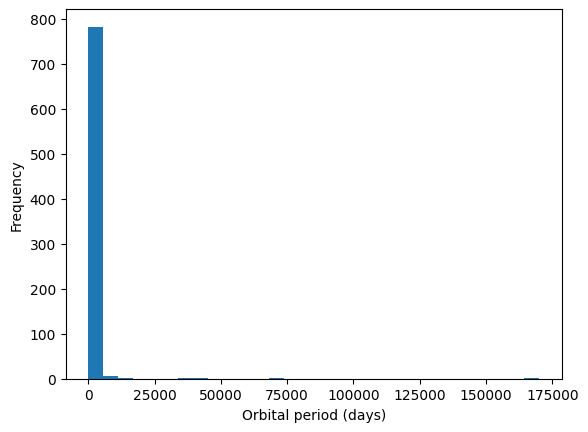

In [52]:
plt.figure()
plt.hist(y_train, bins = 30)
plt.xlabel("Orbital period (days)")
plt.ylabel("Frequency")
plt.show()

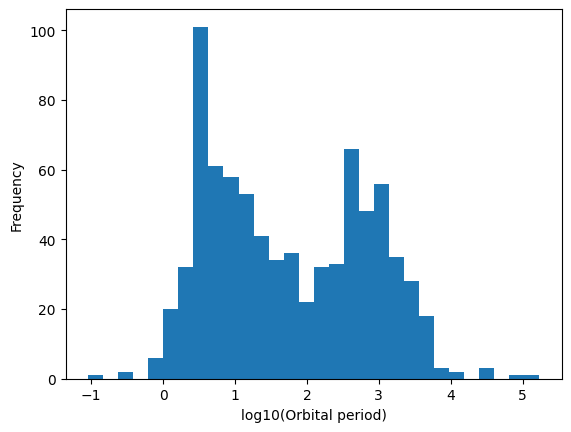

In [53]:
plt.figure()
plt.hist(np.log10(y_train), bins = 30)
plt.xlabel("log10(Orbital period)")
plt.ylabel("Frequency")
plt.show()

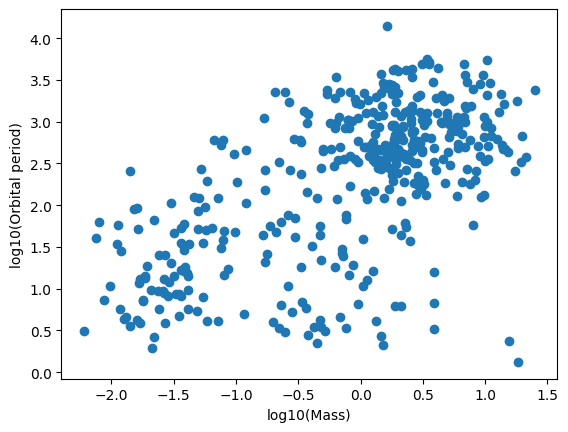

In [54]:
plt.figure()
plt.scatter(np.log10(train_data["mass"]), np.log10(train_data["orbital_period"]))
plt.xlabel("log10(Mass)")
plt.ylabel("log10(Orbital period)")
plt.show()

For masses also, log scale (for both mass and orbital period) make much more sense because they atleast show some clustering rather than all points being concentrated in bottom left (a result of non-scaled plot). But we also need to take into account the fact that most of mass are dominated by one method, while others have mostly missing. We can't yet generalise it to a linear regression model.

In [55]:
print(x_train.shape)
x_train

(793, 3)


,method,mass,distance
230,Radial Velocity,0.0410,39.39
309,Radial Velocity,0.0126,12.83
57,Radial Velocity,NaN,46.84
740,Transit,NaN,NaN
250,Radial Velocity,1.8800,45.52
...,...,...,...
119,Radial Velocity,1.8940,15.10
285,Radial Velocity,1.8000,121.07
881,Transit,NaN,NaN
452,Radial Velocity,0.0580,52.83


In [56]:
from sklearn.impute import SimpleImputer

# 1. Create the imputer
imputer = SimpleImputer(
    strategy="median",
    add_indicator=True
)

# 2. Select numerical features
numeric_train = x_train[["mass", "distance"]]

# 3. Fit and transform training data
numeric_train_imputed = imputer.fit_transform(numeric_train)

print(numeric_train_imputed.shape)
numeric_train_imputed

(793, 4)


array([[4.100e-02, 3.939e+01, 0.000e+00, 0.000e+00],
       [1.260e-02, 1.283e+01, 0.000e+00, 0.000e+00],
       [1.370e+00, 4.684e+01, 1.000e+00, 0.000e+00],
       ...,
       [1.370e+00, 5.593e+01, 1.000e+00, 1.000e+00],
       [5.800e-02, 5.283e+01, 0.000e+00, 0.000e+00],
       [3.500e-02, 1.497e+01, 0.000e+00, 0.000e+00]])

In [57]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(handle_unknown = "ignore")
method_encoded = encoder.fit_transform(x_train[["method"]])
print(method_encoded.shape)
pd.DataFrame(method_encoded.toarray()).head()

(793, 9)


,0,1,2,3,4,5,6,7,8
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Your coding task
Using your existing numeric_train_imputed array:
1. Select only its first two columns using NumPy slicing.
2. Create a StandardScaler.
3. Apply fit_transform() to those two columns.
4. Print the mean and standard deviation of each resulting column.

In [58]:
numeric_train = numeric_train_imputed[:,:2]

In [59]:
from sklearn.preprocessing import StandardScaler
numeric_train_scaled = StandardScaler().fit_transform(numeric_train)
print(f"Mean: {numeric_train_scaled.mean(axis = 0)}, SD: {numeric_train_scaled.std(axis = 0)}")

Mean: [-7.61615795e-17  1.23202555e-17], SD: [1. 1.]


Continuing Checkpoint 4 — Task 4/4
Building the preprocessing pipeline · In progress
Step 1 — Build the numerical pipeline
Using your syntax cheat sheet, create a Pipeline containing these steps in order:
1. SimpleImputer(strategy="median") — without add_indicator=True.
2. StandardScaler().
Name it numeric_pipeline.

Then apply fit_transform() to x_train[["mass", "distance"]] and print its shape.

#5. Preprocessing pipeline

In [60]:
from sklearn.pipeline import Pipeline
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy = "median")),
    ("scaler", StandardScaler())
])
numeric_train_processed = numeric_pipeline.fit_transform(x_train[["mass","distance"]])
print(numeric_train_processed.shape)



(793, 2)


Next step — Preserve missing-value indicators
Now we'll create a separate branch that records which mass and distance values were originally missing.

Scikit-learn provides MissingIndicator for this purpose.

Your task: Apply fit_transform() to indicator, using the original mass and distance columns from x_train.

Print the resulting shape.

Question: What shape do you expect, and what will its two columns represent?

In [61]:
from sklearn.impute import MissingIndicator

indicator = MissingIndicator(features="all")

indicator_train = indicator.fit_transform(x_train[["mass","distance"]])
print(indicator_train.shape)


(793, 2)


Build a ColumnTransformer combining your existing numeric_pipeline, indicator, and encoder objects.

In [62]:
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, ["mass", "distance"]),
    ("indicator", indicator, ["mass", "distance"]),
    ("encoder", encoder, ["method"])
])

X_train_ready = preprocessor.fit_transform(x_train)
print(X_train_ready.shape)

(793, 13)


In [63]:
X_test_ready = preprocessor.transform(x_test)

print(X_train_ready.shape)
print(X_test_ready.shape)

(793, 13)
(199, 13)



#6. **Validation and Documentation**

In [64]:
print(type(X_train_ready))
print(type(X_test_ready))

<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


np.isfinite() checks whether values are finite, excluding both NaN and positive or negative infinity.

In [65]:
print(np.isfinite(X_train_ready).all())
print(np.isfinite(X_test_ready).all())

True
True


We've established that the training and test feature arrays contain valid numerical values.

Now let's verify something more subtle: Did preprocessing preserve the intended feature representation?

Recall that our first two output columns are standardized mass and distance.

Your task: Use NumPy to calculate the mean of those two columns separately for X_train_ready and X_test_ready.

In [67]:
print(X_train_ready[:,:2].mean(axis = 0))
print(X_test_ready[:,:2].mean(axis = 0))
print(X_train_ready.shape)
pd.DataFrame(X_train_ready)

[-1.40002903e-16  7.49015534e-18]
[-0.03502635 -0.1243901 ]
(793, 13)


,0,1,2,3,4,5,6,7,8,9,10,11,12
0,-0.708953,-0.289354,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,-0.718997,-0.338056,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.238954,-0.275693,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,-0.238954,-0.259026,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-0.058593,-0.278114,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
788,-0.053642,-0.333893,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
789,-0.086885,-0.139582,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
790,-0.238954,-0.259026,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
791,-0.702941,-0.264710,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


Important distinction: We've built a model-ready dataset, not a predictive model yet. We still need to train models, measure their errors, and determine whether our features are genuinely useful.